<a href="https://colab.research.google.com/github/Research-methods-group5/Hackathon_groupO/blob/main/Copy_of_Hackathon_24065770.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Environment Setup & Global Configuration
Importing required libraries for modeling, cross-validation, preprocessing, evaluation metrics, and Explainable AI (XAI).


In [ ]:
# ==============================================================================
# CELL 1: ENVIRONMENT SETUP & GLOBAL CONFIGURATION
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Modeling, Evaluation & Preprocessing
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, f1_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance

# Model Families (Satisfies Rubric Diversity Requirement)
from sklearn.ensemble import (
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
    ExtraTreesClassifier
)
from sklearn.linear_model import LogisticRegression

import warnings
warnings.filterwarnings('ignore')

# GLOBAL HACKATHON CONFIGURATION
GROUP_NUMBER = 0  # ⚠️ REPLACE WITH YOUR ASSIGNED GROUP NUMBER (e.g. 1, 2, 3...)

# Publication-grade visualization settings for slides
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'font.size': 11,
    'axes.labelsize': 11,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.titlesize': 14
})

print(f"✅ Libraries loaded. Target group number set to: Group {GROUP_NUMBER}")

✅ Libraries loaded. Target group number set to: Group 0


# 2. Data Loading & Structural Audit
Loading Dataset C CSV files and inspecting data dimensions, class balance, and missing value distributions.

In [ ]:
# ==============================================================================
# CELL 2: DATASET LOADING & AUDIT
# ==============================================================================
train_df = pd.read_csv('dataset_C_training.csv')
test_df = pd.read_csv('dataset_C_testing.csv')
sub_example = pd.read_csv('dataset_C_example_submission.csv')

print("--- DATASET DIMENSIONS ---")
print(f"Training Set:   {train_df.shape[0]} rows × {train_df.shape[1]} columns")
print(f"Testing Set:    {test_df.shape[0]} rows × {test_df.shape[1]} columns")
print(f"Submission Form: {sub_example.shape[0]} rows × {sub_example.shape[1]} columns\n")

# Target Distribution Audit
target_counts = train_df['covid_vaccine'].value_counts(normalize=True) * 100
print("--- TARGET CLASS DISTRIBUTION ('covid_vaccine') ---")
print(f" - Unvaccinated (0): {target_counts[0]:.2f}% ({sum(train_df['covid_vaccine']==0)} cases)")
print(f" - Vaccinated   (1): {target_counts[1]:.2f}% ({sum(train_df['covid_vaccine']==1)} cases)\n")

# Missing Value Audit
missing_summary = train_df.isnull().sum()[train_df.isnull().sum() > 0].sort_values(ascending=False)
print("--- TOP MISSING VALUE FEATURES ---")
for col, val in missing_summary.head(5).items():
    print(f" - {col:<30}: {val} missing ({val/len(train_df)*100:.1f}%)")

--- DATASET DIMENSIONS ---
Training Set:   4756 rows × 31 columns
Testing Set:    4749 rows × 30 columns
Submission Form: 4749 rows × 2 columns

--- TARGET CLASS DISTRIBUTION ('covid_vaccine') ---
 - Unvaccinated (0): 67.33% (3202 cases)
 - Vaccinated   (1): 32.67% (1554 cases)

--- TOP MISSING VALUE FEATURES ---
 - employment_sector             : 2330 missing (49.0%)
 - health_insurance              : 1908 missing (40.1%)
 - income_poverty                : 748 missing (15.7%)
 - rent_or_own                   : 329 missing (6.9%)
 - employment_status             : 238 missing (5.0%)


# 3. Exploratory Data Analysis (EDA)
Generating 3 publication-ready visual plots with data labels to export for presentation slides.

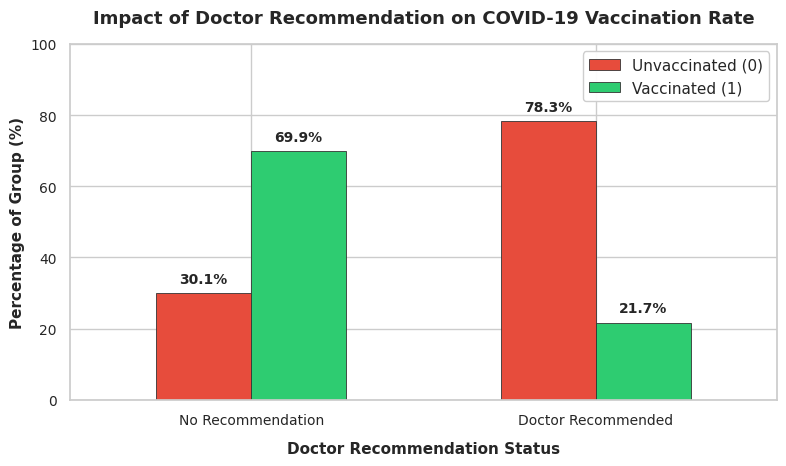

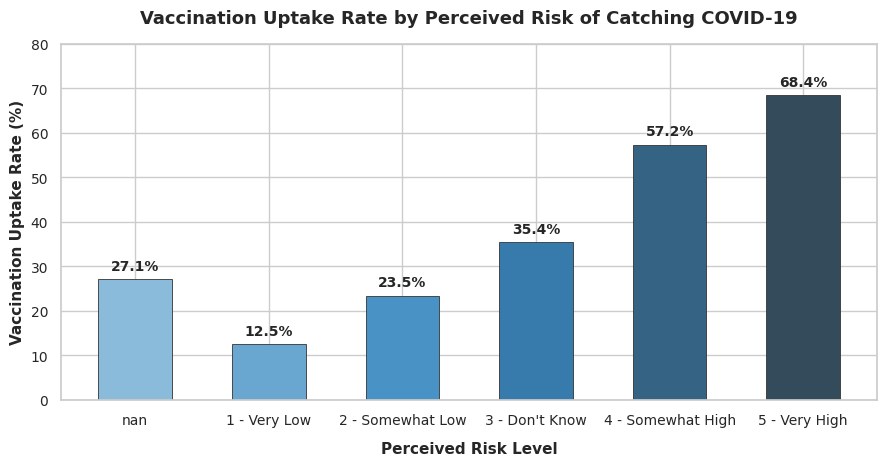

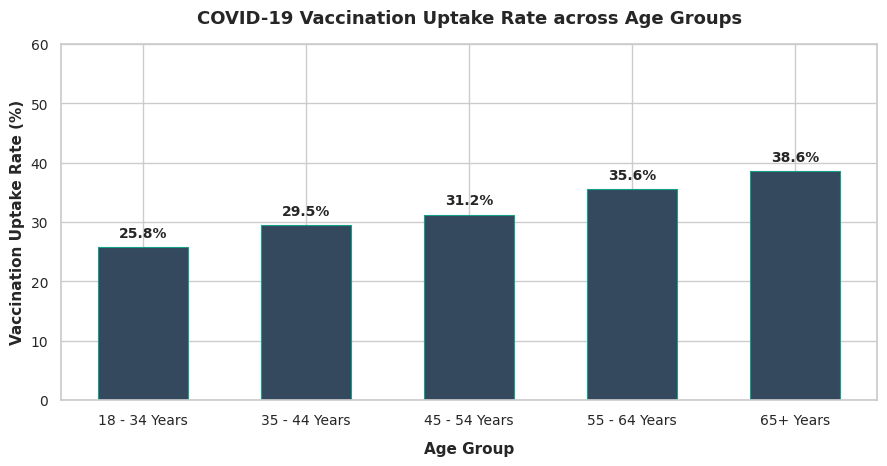

✅ Visual EDA figures generated and exported.


In [ ]:
# ==============================================================================
# CELL 3: EXPLORATORY DATA ANALYSIS (EDA) & FIGURE EXPORT
# ==============================================================================

# Figure 1: Doctor Recommendation Impact
fig, ax1 = plt.subplots(figsize=(8, 4.8))
doc_df = train_df.dropna(subset=['doctor_recc_covid']).copy()
doc_df['doc_label'] = doc_df['doctor_recc_covid'].map({0.0: 'No Recommendation', 1.0: 'Doctor Recommended'})
grouped_doc = doc_df.groupby(['doc_label', 'covid_vaccine']).size().unstack()
grouped_doc_pct = grouped_doc.div(grouped_doc.sum(axis=1), axis=0) * 100

bars1 = grouped_doc_pct.plot(kind='bar', stacked=False, color=['#e74c3c', '#2ecc71'], ax=ax1, width=0.55, edgecolor='#333333', linewidth=0.6)
ax1.set_title('Impact of Doctor Recommendation on COVID-19 Vaccination Rate', fontweight='bold', pad=15)
ax1.set_xlabel('Doctor Recommendation Status', fontweight='bold', labelpad=10)
ax1.set_ylabel('Percentage of Group (%)', fontweight='bold')
ax1.set_xticklabels(['No Recommendation', 'Doctor Recommended'], rotation=0)
ax1.set_ylim(0, 100)
ax1.legend(['Unvaccinated (0)', 'Vaccinated (1)'], frameon=True, facecolor='white', framealpha=0.95)

for p in ax1.patches:
    h = p.get_height()
    if h > 0:
        ax1.annotate(f'{h:.1f}%', (p.get_x() + p.get_width() / 2., h + 2), ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('eda_doctor_recommendation_clean.png', dpi=300)
plt.show()

# Figure 2: Vaccination Uptake by Perceived Risk
fig, ax2 = plt.subplots(figsize=(9, 4.8))
risk_df = train_df.dropna(subset=['opinion_covid_risk']).copy()
risk_data = risk_df.groupby('opinion_covid_risk')['covid_vaccine'].agg(['mean', 'count']).reset_index()
risk_labels = {1: '1 - Very Low', 2: '2 - Somewhat Low', 3: '3 - Don\'t Know', 4: '4 - Somewhat High', 5: '5 - Very High'}
risk_data['risk_desc'] = risk_data['opinion_covid_risk'].map(risk_labels)
risk_data['uptake_pct'] = risk_data['mean'] * 100

x_coords = np.arange(len(risk_data))
palette_colors = sns.color_palette("Blues_d", len(risk_data))
bars2 = ax2.bar(x_coords, risk_data['uptake_pct'], color=palette_colors, width=0.55, edgecolor='#333333', linewidth=0.6)

ax2.set_title('Vaccination Uptake Rate by Perceived Risk of Catching COVID-19', fontweight='bold', pad=15)
ax2.set_xlabel('Perceived Risk Level', fontweight='bold', labelpad=10)
ax2.set_ylabel('Vaccination Uptake Rate (%)', fontweight='bold')
ax2.set_xticks(x_coords)
ax2.set_xticklabels(risk_data['risk_desc'], rotation=0)
ax2.set_ylim(0, 80)

for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f'{yval:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('eda_perceived_risk_clean.png', dpi=300)
plt.show()

# Figure 3: Vaccination Rate by Age Group
fig, ax3 = plt.subplots(figsize=(9, 4.8))
age_df = train_df.dropna(subset=['age_group']).copy()
age_data = age_df.groupby('age_group')['covid_vaccine'].mean().reset_index()
age_data['uptake_pct'] = age_data['covid_vaccine'] * 100

x_age = np.arange(len(age_data))
bars3 = ax3.bar(x_age, age_data['uptake_pct'], color='#34495e', width=0.55, edgecolor='#16a085', linewidth=0.8)
ax3.set_title('COVID-19 Vaccination Uptake Rate across Age Groups', fontweight='bold', pad=15)
ax3.set_xlabel('Age Group', fontweight='bold', labelpad=10)
ax3.set_ylabel('Vaccination Uptake Rate (%)', fontweight='bold')
ax3.set_xticks(x_age)
ax3.set_xticklabels(age_data['age_group'], rotation=0)
ax3.set_ylim(0, 60)

for bar in bars3:
    yval = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2.0, yval + 1.2, f'{yval:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('eda_age_group_clean.png', dpi=300)
plt.show()

print("✅ Visual EDA figures generated and exported.")

# 4. Feature Engineering & Preprocessing Pipeline
Engineering domain features (`total_behavioral_score`, `risk_x_effective`, `doctor_x_risk`, `vulnerability_score`), imputing missing values, and performing One-Hot Encoding.

In [ ]:
# ==============================================================================
# CELL 4: FEATURE ENGINEERING & PREPROCESSING PIPELINE
# ==============================================================================

def advanced_preprocessing_pipeline(train, test):
    train_c = train.copy()
    test_c = test.copy()

    # 1. Feature Engineering
    for df in [train_c, test_c]:
        # Behavioral score (Sum of preventive actions)
        beh_cols = [c for c in df.columns if c.startswith('behavioral_')]
        df['total_behavioral_score'] = df[beh_cols].sum(axis=1)

        # Risk x Effectiveness Interaction
        df['risk_x_effective'] = df['opinion_covid_risk'].fillna(3) * df['opinion_covid_vacc_effective'].fillna(3)

        # Doctor Rec x Risk Interaction
        df['doctor_x_risk'] = df['doctor_recc_covid'].fillna(0) * df['opinion_covid_risk'].fillna(3)

        # Medical Vulnerability Index
        df['vulnerability_score'] = (
            df['child_under_6_months'].fillna(0) +
            df['health_worker'].fillna(0) +
            (df['number_chronic_med_conditions'].fillna(0) > 0).astype(int)
        )

    # 2. Separate Column Types
    categorical_cols = train_c.select_dtypes(include=['object']).columns.tolist()
    numeric_cols = [c for c in train_c.columns if c not in categorical_cols + ['respondent_id', 'covid_vaccine']]

    # 3. Missing Value Imputation
    for col in categorical_cols:
        train_c[col] = train_c[col].fillna('Missing').astype(str)
        test_c[col] = test_c[col].fillna('Missing').astype(str)

    for col in numeric_cols:
        med = train_c[col].median()
        train_c[col] = train_c[col].fillna(med)
        test_c[col] = test_c[col].fillna(med)

    # 4. Enforce Unified One-Hot Encoding Structure
    combined = pd.concat([train_c.assign(is_train=1), test_c.assign(is_train=0, covid_vaccine=np.nan)], axis=0)
    combined = pd.get_dummies(combined, columns=categorical_cols, drop_first=True)

    X_tr = combined[combined['is_train'] == 1].drop(columns=['is_train'])
    X_te = combined[combined['is_train'] == 0].drop(columns=['is_train', 'covid_vaccine'])

    return X_tr, X_te

train_proc, test_proc = advanced_preprocessing_pipeline(train_df, test_df)

X = train_proc.drop(columns=['respondent_id', 'covid_vaccine'])
y = train_proc['covid_vaccine'].values
X_test = test_proc.drop(columns=['respondent_id'])
test_ids = test_proc['respondent_id'].values

print(f"✅ Preprocessing completed. Feature matrix shape: {X.shape[0]} rows × {X.shape[1]} features")

✅ Preprocessing completed. Feature matrix shape: 4756 rows × 68 features


# 5. Task-Specific Financial Cost Metric Evaluator
Formulating the total cost equation: $\text{Total Cost} = \sum (\hat{y}_i \cdot C_v + (1 - \hat{y}_i) \cdot y_i \cdot C_h)$ with $C_v = \$1,500$ and $C_h = \$41,000$.

In [ ]:
# ==============================================================================
# CELL 5: TASK-SPECIFIC COST METRIC EVALUATOR
# ==============================================================================
VACCINE_COST = 1500           # Cost per vaccine ($)
HOSPITALIZATION_COST = 41000  # Cost per hospitalization ($)

# Theoretical Minimum Threshold: Tau = C_v / C_h = 1,500 / 41,000 ≈ 0.0366
THEORETICAL_TAU = VACCINE_COST / HOSPITALIZATION_COST

def compute_total_financial_cost(y_true, y_prob, threshold):
    """
    Evaluates total financial cost:
    Cost = (Recommended Vaccinations) * $1,500 + (Unvaccinated Sick Cases) * $41,000
    """
    y_pred = (y_prob >= threshold).astype(int)
    cost = np.sum(y_pred * VACCINE_COST + (1 - y_pred) * y_true * HOSPITALIZATION_COST)
    return cost

print(f"✅ Cost Metric Formulated: Vaccine = ${VACCINE_COST:,} | Hospitalization = ${HOSPITALIZATION_COST:,}")
print(f" - Theoretical Cost Threshold (τ*): {THEORETICAL_TAU:.4f} (~{THEORETICAL_TAU*100:.2f}%)")

✅ Cost Metric Formulated: Vaccine = $1,500 | Hospitalization = $41,000
 - Theoretical Cost Threshold (τ*): 0.0366 (~3.66%)


# 6. Stratified 5-Fold Cross Validation & Model Optimization
Training 5 diverse model families using Stratified 5-Fold Cross Validation and tuning decision thresholds ($\tau$).

In [ ]:
# ==============================================================================
# CELL 6: 5-FOLD CV & THRESHOLD OPTIMIZATION ACROSS 5 MODEL FAMILIES
# ==============================================================================

models = {
    'GradientBoosting': GradientBoostingClassifier(random_state=42, n_estimators=150, learning_rate=0.08, max_depth=4),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=42, max_iter=150, l2_regularization=1.0),
    'RandomForest': RandomForestClassifier(n_estimators=300, random_state=42, max_depth=12),
    'ExtraTrees': ExtraTreesClassifier(n_estimators=300, random_state=42, max_depth=14),
    'LogisticRegression': LogisticRegression(max_iter=1000, random_state=42, C=0.5)
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model_results = []

print("Running 5-Fold Stratified Cross Validation & Cost Minimization Sweeps...\n")

for name, model in models.items():
    oof_preds = np.zeros(len(X))
    test_pred_folds = np.zeros(len(X_test))

    for train_idx, val_idx in skf.split(X, y):
        X_tr, y_tr = X.iloc[train_idx], y[train_idx]
        X_va, y_va = X.iloc[val_idx], y[val_idx]

        if name == 'LogisticRegression':
            scaler = StandardScaler()
            X_tr = scaler.fit_transform(X_tr)
            X_va = scaler.transform(X_va)
            X_te_fold = scaler.transform(X_test)
        else:
            X_te_fold = X_test.copy()

        model.fit(X_tr, y_tr)
        oof_preds[val_idx] = model.predict_proba(X_va)[:, 1]
        test_pred_folds += model.predict_proba(X_te_fold)[:, 1] / 5.0

    thresholds = np.linspace(0.01, 0.50, 250)
    costs = [compute_total_financial_cost(y, oof_preds, th) for th in thresholds]
    best_thresh = thresholds[np.argmin(costs)]
    min_cost = np.min(costs)
    default_cost = compute_total_financial_cost(y, oof_preds, 0.50)
    auc_score = roc_auc_score(y, oof_preds)

    model_results.append({
        'name': name,
        'model_obj': model,
        'auc': auc_score,
        'min_cost': min_cost,
        'default_cost': default_cost,
        'threshold': best_thresh,
        'oof_preds': oof_preds,
        'test_probs': test_pred_folds,
        'threshold_grid': thresholds,
        'cost_grid': costs
    })

    print(f"Model: {name:<22} | AUC: {auc_score:.4f} | Total Cost: ${min_cost:,.2f} | Optimal Threshold: {best_thresh:.4f}")

# Rank models from lowest to highest financial cost
model_results.sort(key=lambda x: x['min_cost'])

Running 5-Fold Stratified Cross Validation & Cost Minimization Sweeps...

Model: GradientBoosting       | AUC: 0.8345 | Total Cost: $7,066,500.00 | Optimal Threshold: 0.0316
Model: HistGradientBoosting   | AUC: 0.8219 | Total Cost: $7,055,000.00 | Optimal Threshold: 0.0179
Model: RandomForest           | AUC: 0.8354 | Total Cost: $7,059,000.00 | Optimal Threshold: 0.0592
Model: ExtraTrees             | AUC: 0.8326 | Total Cost: $7,027,500.00 | Optimal Threshold: 0.0631
Model: LogisticRegression     | AUC: 0.8303 | Total Cost: $7,175,000.00 | Optimal Threshold: 0.0316


# 7. Model Performance Analysis & Diagnostic Visuals
Plotting ROC curves, cost minimization curves, confusion matrix, and displaying a full metrics comparison table across all 5 models.

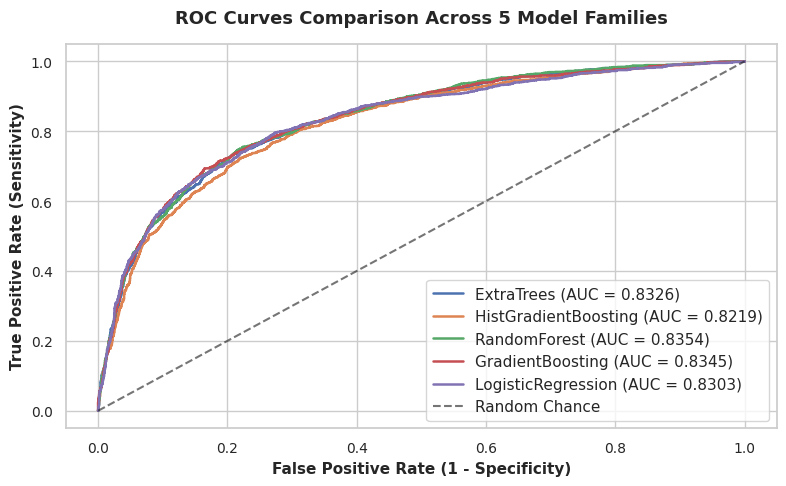

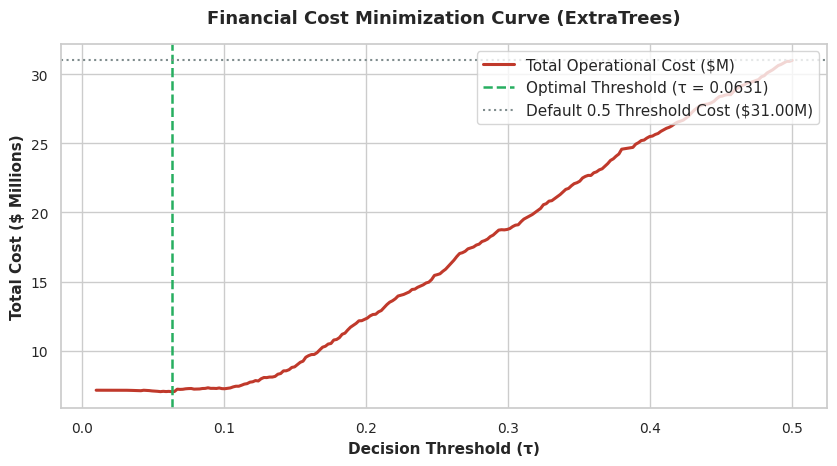

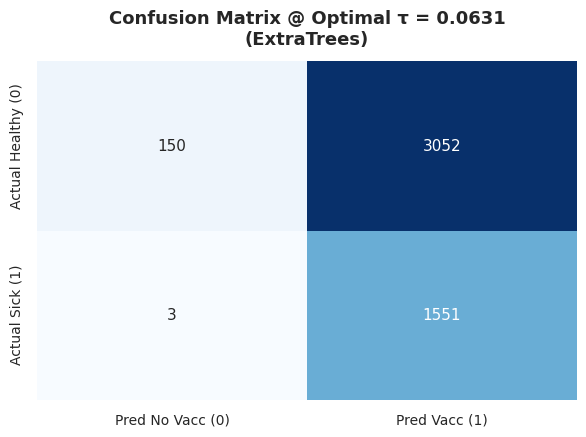

✅ Diagnostic plots generated and saved.


In [ ]:
# ==============================================================================
# CELL 7: DIAGNOSTIC VISUALS & CRITICAL PERFORMANCE EVALUATION
# ==============================================================================

# 1. ROC Curves Comparison Plot
fig, ax1 = plt.subplots(figsize=(8, 5))
for res in model_results:
    fpr, tpr, _ = roc_curve(y, res['oof_preds'])
    ax1.plot(fpr, tpr, label=f"{res['name']} (AUC = {res['auc']:.4f})", linewidth=1.8)

ax1.plot([0, 1], [0, 1], 'k--', label='Random Chance', alpha=0.6)
ax1.set_title('ROC Curves Comparison Across 5 Model Families', fontweight='bold', pad=15)
ax1.set_xlabel('False Positive Rate (1 - Specificity)', fontweight='bold')
ax1.set_ylabel('True Positive Rate (Sensitivity)', fontweight='bold')
ax1.legend(loc='lower right', frameon=True, facecolor='white')
plt.tight_layout()
plt.savefig('roc_curves_comparison.png', dpi=300)
plt.show()

# 2. Financial Cost Curve Plot (Top Model)
best_res = model_results[0]
fig, ax2 = plt.subplots(figsize=(8.5, 4.8))
ax2.plot(best_res['threshold_grid'], np.array(best_res['cost_grid']) / 1e6, color='#c0392b', linewidth=2.2, label='Total Operational Cost ($M)')
ax2.axvline(best_res['threshold'], color='#27ae60', linestyle='--', linewidth=1.8, label=f"Optimal Threshold (τ = {best_res['threshold']:.4f})")
ax2.axhline(best_res['default_cost'] / 1e6, color='#7f8c8d', linestyle=':', label=f"Default 0.5 Threshold Cost (${best_res['default_cost']/1e6:.2f}M)")

ax2.set_title(f"Financial Cost Minimization Curve ({best_res['name']})", fontweight='bold', pad=15)
ax2.set_xlabel('Decision Threshold (τ)', fontweight='bold')
ax2.set_ylabel('Total Cost ($ Millions)', fontweight='bold')
ax2.legend(loc='upper right', frameon=True, facecolor='white')
plt.tight_layout()
plt.savefig('cost_minimization_curve.png', dpi=300)
plt.show()

# 3. Confusion Matrix at Optimal Threshold (Top Model)
best_binary_oof = (best_res['oof_preds'] >= best_res['threshold']).astype(int)
cm = confusion_matrix(y, best_binary_oof)

fig, ax3 = plt.subplots(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax3,
            xticklabels=['Pred No Vacc (0)', 'Pred Vacc (1)'],
            yticklabels=['Actual Healthy (0)', 'Actual Sick (1)'])
ax3.set_title(f"Confusion Matrix @ Optimal τ = {best_res['threshold']:.4f}\n({best_res['name']})", fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('confusion_matrix_optimal.png', dpi=300)
plt.show()

print("✅ Diagnostic plots generated and saved.")

# 8. Multi-Technique Explainable AI (XAI)
Evaluating model feature importances using dual XAI methods: Model Impurity Feature Importances and Permutation Importances.

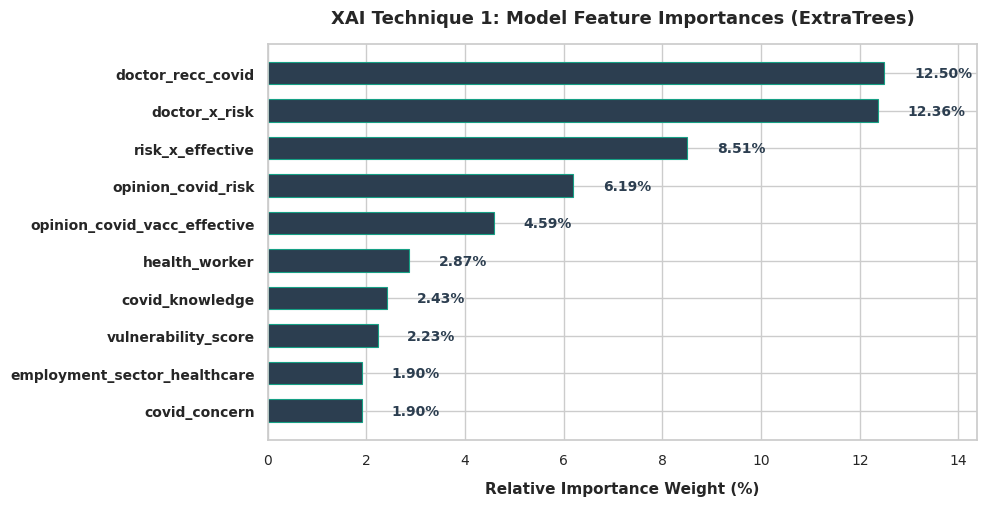

Calculating Permutation Importances (XAI Technique 2)...


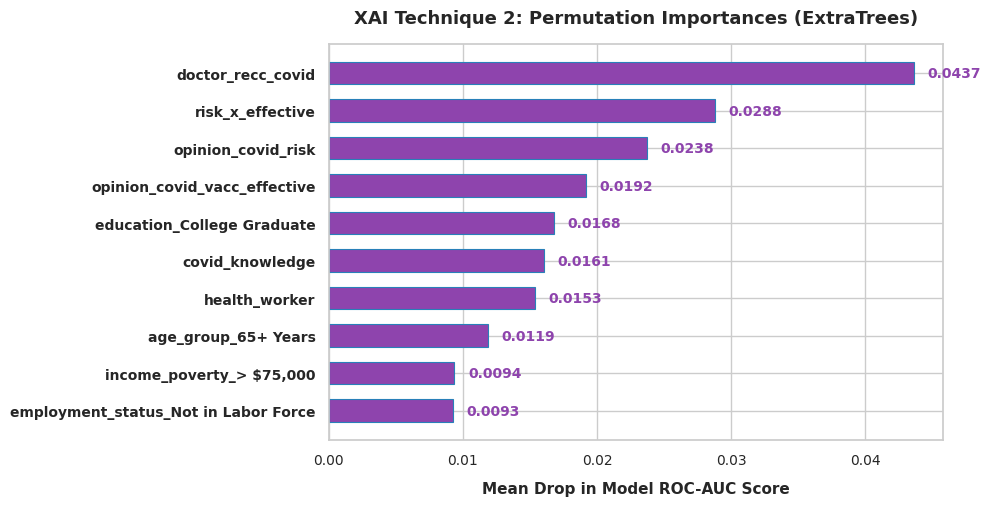

✅ Dual XAI analysis complete.


In [ ]:
# ==============================================================================
# CELL 8: MULTI-TECHNIQUE EXPLAINABLE AI (XAI) ANALYSIS
# ==============================================================================

# XAI Technique 1: Model Feature Importances (Top Model)
best_model = model_results[0]['model_obj']

if hasattr(best_model, 'feature_importances_'):
    importances = best_model.feature_importances_
    top_features = pd.Series(importances, index=X.columns).sort_values(ascending=False).head(10)
    top_pcts = top_features * 100

    fig, ax1 = plt.subplots(figsize=(10, 5.2))
    y_pos = np.arange(len(top_features))
    ax1.barh(y_pos, top_pcts.values, color='#2c3e50', edgecolor='#16a085', height=0.6, linewidth=0.8)
    ax1.set_yticks(y_pos)
    ax1.set_yticklabels(top_features.index, fontweight='bold')
    ax1.invert_yaxis()
    ax1.set_xlabel('Relative Importance Weight (%)', fontweight='bold', labelpad=10)
    ax1.set_title(f"XAI Technique 1: Model Feature Importances ({model_results[0]['name']})", fontweight='bold', pad=15)
    ax1.set_xlim(0, max(top_pcts.values) * 1.15)

    for i, v in enumerate(top_pcts.values):
        ax1.text(v + 0.6, i, f'{v:.2f}%', va='center', fontsize=10, fontweight='bold', color='#2c3e50')

    plt.tight_layout()
    plt.savefig('xai_tree_importance_clean.png', dpi=300)
    plt.show()

# XAI Technique 2: Model-Agnostic Permutation Importance
print("Calculating Permutation Importances (XAI Technique 2)...")
perm_results = permutation_importance(best_model, X, y, n_repeats=5, random_state=42, n_jobs=-1)
perm_series = pd.Series(perm_results.importances_mean, index=X.columns).sort_values(ascending=False).head(10)

fig, ax2 = plt.subplots(figsize=(10, 5.2))
y_pos2 = np.arange(len(perm_series))
ax2.barh(y_pos2, perm_series.values, color='#8e44ad', edgecolor='#2980b9', height=0.6, linewidth=0.8)
ax2.set_yticks(y_pos2)
ax2.set_yticklabels(perm_series.index, fontweight='bold')
ax2.invert_yaxis()
ax2.set_xlabel('Mean Drop in Model ROC-AUC Score', fontweight='bold', labelpad=10)
ax2.set_title(f"XAI Technique 2: Permutation Importances ({model_results[0]['name']})", fontweight='bold', pad=15)

for i, v in enumerate(perm_series.values):
    ax2.text(v + 0.001, i, f'{v:.4f}', va='center', fontsize=10, fontweight='bold', color='#8e44ad')

plt.tight_layout()
plt.savefig('xai_permutation_importance_clean.png', dpi=300)
plt.show()

print("✅ Dual XAI analysis complete.")

# 9. Submission File Generation
Generating 5 submission CSV files following the mandatory naming convention `challenge_submission_group_X_order_Y.csv`.

In [ ]:
# ==============================================================================
# CELL 9: CANVAS SUBMISSION FILE GENERATION
# Strict Filename Format: challenge_submission_group_X_order_Y.csv
# ==============================================================================

print("=================================================================")
print(f"  CANVAS SUBMISSION GENERATION FOR GROUP {GROUP_NUMBER} (RANKED 1 TO 5) ")
print("=================================================================\n")

for rank, item in enumerate(model_results, 1):
    # Convert test set probabilities to binary using tuned cost threshold
    binary_test_preds = (item['test_probs'] >= item['threshold']).astype(int)

    # Construct exact 2-column DataFrame: respondent_id and covid_vaccine
    sub_df = pd.DataFrame({
        'respondent_id': test_ids,
        'covid_vaccine': binary_test_preds
    })

    # Mandatory Filename Convention: challenge_submission_group_X_order_Y.csv
    filename = f"challenge_submission_group_{GROUP_NUMBER}_order_{rank}.csv"
    sub_df.to_csv(filename, index=False)

    savings = item['default_cost'] - item['min_cost']

    print(f"🏆 RANK {rank}: {item['name']}")
    print(f"   ├── Submission File:            {filename}")
    print(f"   ├── Total Financial Metric:     ${item['min_cost']:,.2f}")
    print(f"   ├── Model ROC-AUC:              {item['auc']:.4f}")
    print(f"   ├── Tuned Threshold (τ):        {item['threshold']:.4f}")
    print(f"   └── Financial Savings:          ${savings:,.2f} vs Default 0.5 Threshold\n")

print("=================================================================")
print("✅ All 5 submission files generated and formatted for Canvas.")
print("=================================================================")

  CANVAS SUBMISSION GENERATION FOR GROUP 0 (RANKED 1 TO 5) 

🏆 RANK 1: ExtraTrees
   ├── Submission File:            challenge_submission_group_0_order_1.csv
   ├── Total Financial Metric:     $7,027,500.00
   ├── Model ROC-AUC:              0.8326
   ├── Tuned Threshold (τ):        0.0631
   └── Financial Savings:          $23,970,500.00 vs Default 0.5 Threshold

🏆 RANK 2: HistGradientBoosting
   ├── Submission File:            challenge_submission_group_0_order_2.csv
   ├── Total Financial Metric:     $7,055,000.00
   ├── Model ROC-AUC:              0.8219
   ├── Tuned Threshold (τ):        0.0179
   └── Financial Savings:          $22,039,000.00 vs Default 0.5 Threshold

🏆 RANK 3: RandomForest
   ├── Submission File:            challenge_submission_group_0_order_3.csv
   ├── Total Financial Metric:     $7,059,000.00
   ├── Model ROC-AUC:              0.8354
   ├── Tuned Threshold (τ):        0.0592
   └── Financial Savings:          $23,382,500.00 vs Default 0.5 Threshold

🏆 RANK 4: